### Import Data P1 ke Neo4j

Cek Koneksi

In [ ]:
from neo4j import GraphDatabase
from getpass import getpass

# Sesuaikan dengan informasi instance RetailRocket_P1
bolt_uri = "bolt://127.0.0.1:7687"
neo4j_user = "neo4j"
neo4j_password = getpass("Password instance RetailRocket_P1: ")

driver = GraphDatabase.driver(
    bolt_uri,
    auth=(neo4j_user, neo4j_password)
)

driver.verify_connectivity()
print("Koneksi ke Neo4j berhasil!")

with driver.session(database="neo4j") as session:
    result = session.run("""
        MATCH (n)
        RETURN count(n) AS jumlah_node
    """)
    print("Jumlah node saat ini:", result.single()["jumlah_node"])


Definisikan Fungsi Impor

In [ ]:

def create_constraints(session):
    session.run("""
        CREATE CONSTRAINT visitor_id_unique IF NOT EXISTS
        FOR (v:Visitor)
        REQUIRE v.visitorid IS UNIQUE
    """)

    session.run("""
        CREATE CONSTRAINT item_id_unique IF NOT EXISTS
        FOR (i:item)
        REQUIRE i.itemid IS UNIQUE
    """)


def import_batch(tx, records):
    cypher_query = """
    UNWIND $batch AS row

    MERGE (v:Visitor {visitorid: row.visitorid})
    MERGE (i:item {itemid: row.itemid})

    FOREACH (_ IN CASE
        WHEN row.event = 'view' THEN [1]
        ELSE []
    END |
        CREATE (v)-[:VIEWED {
            timestamp: row.timestamp
        }]->(i)
    )

    FOREACH (_ IN CASE
        WHEN row.event = 'addtocart' THEN [1]
        ELSE []
    END |
        CREATE (v)-[:ADDED_TO_CART {
            timestamp: row.timestamp
        }]->(i)
    )

    FOREACH (_ IN CASE
        WHEN row.event = 'transaction' THEN [1]
        ELSE []
    END |
        CREATE (v)-[:BOUGHT {
            timestamp: row.timestamp,
            transactionid: row.transactionid
        }]->(i)
    )

    RETURN count(row) AS processed_rows
    """

    result = tx.run(cypher_query, batch=records)
    return result.single()["processed_rows"]


Import Data P1

In [ ]:

import pandas as pd
from tqdm.auto import tqdm
from pathlib import Path

csv_file_path = Path("events_P1.csv")
batch_size = 1000

if not csv_file_path.exists():
    raise FileNotFoundError(
        f"File tidak ditemukan: {csv_file_path.resolve()}"
    )

total_rows = 0

with driver.session(database="neo4j") as session:
    create_constraints(session)

    chunks = pd.read_csv(
        csv_file_path,
        chunksize=batch_size
    )

    for chunk in tqdm(chunks, desc="Mengimpor P1"):
        required_columns = {
            "timestamp", "visitorid", "event",
            "itemid", "transactionid"
        }

        missing_columns = required_columns - set(chunk.columns)
        if missing_columns:
            raise ValueError(
                f"Kolom tidak ditemukan: {missing_columns}"
            )

        chunk["event"] = (
            chunk["event"].astype(str).str.strip().str.lower()
        )

        chunk["transactionid"] = (
            chunk["transactionid"].fillna("").astype(str)
        )

        chunk = chunk[
            chunk["event"].isin(
                ["view", "addtocart", "transaction"]
            )
        ]

        records = chunk.to_dict(orient="records")

        if records:
            processed = session.execute_write(
                import_batch, records
            )
            total_rows += processed

print("Impor P1 selesai.")
print(f"Jumlah baris diproses: {total_rows:,}")


### (Soal 4 & 5) VSM User dan Item

Membentuk matriks interaksi SVM

In [14]:

from scipy.sparse import coo_matrix

# 1. Berikan indeks numerik untuk setiap Visitor dan Item
visitor_codes, visitor_ids = pd.factorize(
    df["visitorid"], sort=True
)

item_codes, item_ids = pd.factorize(
    df["itemid"], sort=True
)

# 2. Bentuk matriks interaksi awal
# Baris = Visitor, kolom = Item
VSM_user = coo_matrix(
    (
        np.ones(len(df), dtype=np.int32),
        (visitor_codes, item_codes)
    ),
    shape=(len(visitor_ids), len(item_ids))
).tocsr()

# 3. Gabungkan pasangan Visitor-Item yang berulang
# Nilai hasil penjumlahan diubah menjadi biner: 1
VSM_user.data[:] = 1

# 4. Buat representasi VSM Item
VSM_item = VSM_user.T.tocsr()

# 5. Tampilkan informasi matriks
print("=== VSM USER ===")
print("Shape:", VSM_user.shape)
print("Jumlah pasangan interaksi unik:", VSM_user.nnz)

print("\n=== VSM ITEM ===")
print("Shape:", VSM_item.shape)
print("Jumlah pasangan interaksi unik:", VSM_item.nnz)

# 6. Hitung kepadatan matriks
total_kombinasi = VSM_user.shape[0] * VSM_user.shape[1]
density = VSM_user.nnz / total_kombinasi

print(f"\nDensity matriks: {density:.8%}")


=== VSM USER ===
Shape: (861498, 189511)
Jumlah pasangan interaksi unik: 1291947

=== VSM ITEM ===
Shape: (189511, 861498)
Jumlah pasangan interaksi unik: 1291947

Density matriks: 0.00079133%


Membuat Visualisasi 25 simpul terpilih

In [15]:
import networkx as nx
import matplotlib.pyplot as plt
from sklearn.metrics.pairwise import cosine_similarity

def visualize_projection(vsm, node_ids, title, top_n=25, top_k=3):
    # Pilih simpul dengan jumlah interaksi terbanyak
    degrees = np.asarray(vsm.sum(axis=1)).ravel()
    selected_idx = np.argsort(degrees)[-top_n:][::-1]

    # Ambil sebagian kecil matriks agar perhitungan tetap ringan
    sample_matrix = vsm[selected_idx]

    # Hitung cosine similarity hanya untuk sampel
    similarities = cosine_similarity(sample_matrix)

    # Bentuk graf proyeksi
    G = nx.Graph()

    for idx in selected_idx:
        G.add_node(int(node_ids[idx]))

    # Hubungkan setiap simpul dengan tetangga paling mirip
    for i in range(len(selected_idx)):
        neighbors = np.argsort(similarities[i])[::-1]

        added = 0
        for j in neighbors:
            if i == j:
                continue

            score = similarities[i, j]

            # Abaikan simpul yang tidak memiliki kemiripan
            if score <= 0:
                continue

            G.add_edge(
                int(node_ids[selected_idx[i]]),
                int(node_ids[selected_idx[j]]),
                weight=float(score)
            )

            added += 1
            if added >= top_k:
                break

    # Visualisasi graf
    plt.figure(figsize=(12, 8))
    pos = nx.spring_layout(G, seed=42)

    nx.draw_networkx(
        G,
        pos,
        node_size=450,
        font_size=7,
        with_labels=True
    )

    plt.title(title)
    plt.axis("off")
    plt.show()

    print("Jumlah simpul pada visualisasi:", G.number_of_nodes())
    print("Jumlah sisi pada visualisasi:", G.number_of_edges())

    return G


Visualisasi Graf User - Item

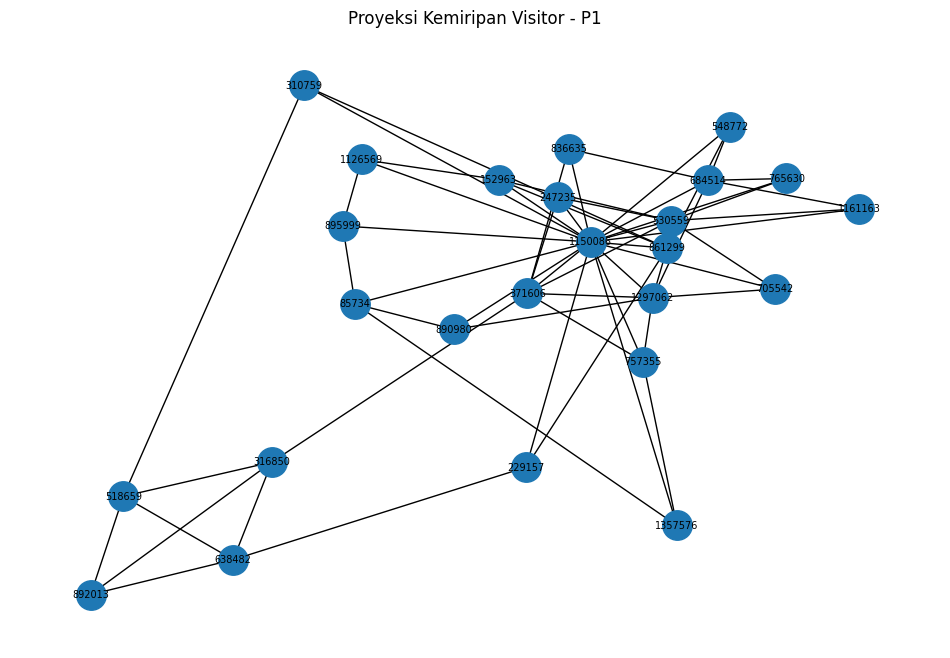

Jumlah simpul pada visualisasi: 25
Jumlah sisi pada visualisasi: 59


In [16]:
G_user = visualize_projection(
    VSM_user,
    visitor_ids,
    title="Proyeksi Kemiripan Visitor - P1",
    top_n=25,
    top_k=3
)

Visualisasi Graf Item - User

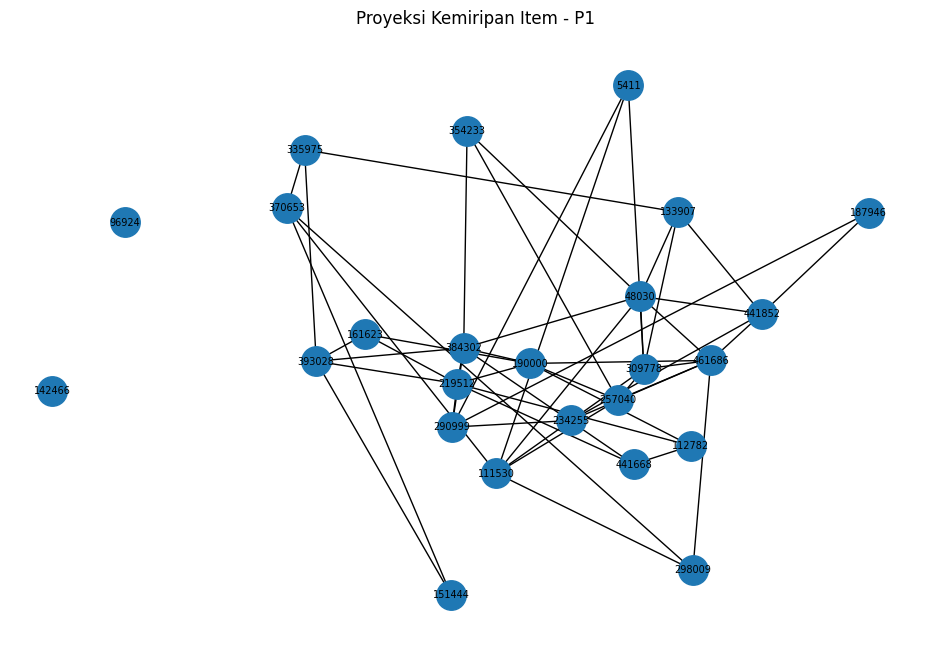

Jumlah simpul pada visualisasi: 25
Jumlah sisi pada visualisasi: 51


In [17]:
G_item = visualize_projection(
    VSM_item,
    item_ids,
    title="Proyeksi Kemiripan Item - P1",
    top_n=25,
    top_k=3
)

### (Soal 7) Menghitung Similarity

In [19]:
from sklearn.metrics.pairwise import cosine_similarity
import numpy as np
import pandas as pd

# 1. Hitung jumlah Visitor unik yang berinteraksi dengan setiap item
jumlah_interaksi = np.asarray(
    VSM_item.sum(axis=1)
).ravel()

# 2. Pilih item dengan jumlah interaksi terbanyak sebagai acuan
ref_idx = int(np.argmax(jumlah_interaksi))
reference_item_id = int(item_ids[ref_idx])

print("Item acuan:", reference_item_id)
print("Jumlah interaksi unik:", int(jumlah_interaksi[ref_idx]))

# 3. Hitung cosine similarity item acuan terhadap seluruh item
similarities = cosine_similarity(
    VSM_item[ref_idx],
    VSM_item
).ravel()

# 4. Ambil lima item dengan similarity tertinggi,
#    tidak termasuk item acuan itu sendiri
similarities[ref_idx] = -1

top_indices = np.argsort(similarities)[::-1][:5]

# 5. Susun hasil
hasil_similarity = pd.DataFrame({
    "reference_itemid": reference_item_id,
    "similar_itemid": [int(item_ids[i]) for i in top_indices],
    "similarity": similarities[top_indices],
    "jumlah_interaksi": [
        int(jumlah_interaksi[i]) for i in top_indices
    ]
})

display(hasil_similarity)


Item acuan: 5411
Jumlah interaksi unik: 1850


,reference_itemid,similar_itemid,similarity,jumlah_interaksi
0,5411,33030,0.150459,117
1,5411,33956,0.085248,36
2,5411,37807,0.084550,40
3,5411,358234,0.081391,47
4,5411,375492,0.065159,165


### (Soal 8) Menulis Nilai Similarity ke graf Neo4j

In [24]:
records_similarity = hasil_similarity.to_dict(orient="records")

cypher_simpan = """
UNWIND $rows AS row
MATCH (source:item {itemid: row.reference_itemid})
MATCH (target:item {itemid: row.similar_itemid})

MERGE (source)-[r:SIMILAR_TO]->(target)

SET r.similarity = row.similarity,
    r.method = 'cosine_similarity',
    r.period = 'P1'

RETURN source.itemid AS item_acuan,
       target.itemid AS item_mirip,
       r.similarity AS similarity,
       r.method AS metode,
       r.period AS periode

ORDER BY similarity DESC
"""

with driver.session(database="neo4j") as session:
    result = session.run(
        cypher_simpan,
        rows=records_similarity
    )
    hasil_simpan = [record.data() for record in result]

df_hasil_simpan = pd.DataFrame(hasil_simpan)
display(df_hasil_simpan)

,item_acuan,item_mirip,similarity,metode,periode
0,5411,33030,0.150459,cosine_similarity,P1
1,5411,33956,0.085248,cosine_similarity,P1
2,5411,37807,0.084550,cosine_similarity,P1
3,5411,358234,0.081391,cosine_similarity,P1
4,5411,375492,0.065159,cosine_similarity,P1
